# 06 · Results on the 134-predictor paper dataset

Replication and extension of Lin, Lin & Chuang (2026), *Toward practical screening of mortality
risk: Insights from interpretable machine learning in NHANES*
([doi:10.1016/j.ijcrp.2026.200595](https://doi.org/10.1016/j.ijcrp.2026.200595)).

**This notebook only displays results. It does not train anything.** The computation lives in
scripts so that it always runs top to bottom and can be tested:

| Step | Command | Time |
|---|---|---|
| Build the 134-predictor dataset from raw CDC files | `.venv/bin/python src/paper134_build.py` | 1 min |
| Check the dataset against raw files | `.venv/bin/python -m unittest tests/test_paper134_candidate.py` | 10 s |
| Train models and compute every table and figure below | `.venv/bin/python src/paper134_analysis.py` | about 20 min |
| Check the hand-written statistics | `.venv/bin/python -m unittest tests/test_paper134_stats.py` | 1 s |

The sections follow the task list for this stage of the project:

1. Preprocessing as in the paper
2. Four models: GLM, Random Forest, XGBoost, LightGBM
3. Calibration (paper 2.5) and survival analysis (paper 2.7)
4. A simpler model from feature importance (paper 2.8)
5. Research question: do models agree on what matters for each person?
6. Feature importance beyond SHAP
7. SHAP replication (paper 2.6)
8. Validation across survey cycles (paper 2.9)
9. What is still open

Cohort: 9,957 adults aged 40+, NHANES 1999–2004; outcome: death within five years (1,293 deaths).

In [1]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, display

R = Path("../results/models_v0.2")
info = json.load(open(R / "summary.json"))
assert not info["fast_mode"], "Results are from a --fast run; rerun src/paper134_analysis.py"
pd.set_option("display.max_columns", 40, "display.max_colwidth", 70, "display.width", 200)


def table(name, **kw):
    return pd.read_csv(R / name, **kw)


def fig(name, width=900):
    display(Image(filename=str(R / name), width=width))


print(f"Participants: {info['n']:,}   deaths: {info['deaths']:,}   "
      f"people with SHAP explanations: {info['people_explained']:,}")

Participants: 9,957   deaths: 1,293   people with SHAP explanations: 1,500


## 1. Preprocessing as in the paper

Paper section 2.3, and what this project does:

| Paper | Here |
|---|---|
| Categorical variables one-hot encoded inside each training fold, unseen categories ignored | Same |
| Categorical gaps filled with the most frequent category | Same |
| XGBoost receives missing values as they are | Same |
| "The remaining algorithms" (GLM, Random Forest, LightGBM): iterative multivariable imputation inside each fold | Same, all predictors, 10 rounds |
| No feature scaling for tree-based models | Same. Logistic regression inputs are scaled, which the paper does not rule out; an unscaled version is reported below for comparison |

**One necessary departure.** The 30 DNA-methylation variables are missing together for 75% of
people and are close to linear combinations of one another. Unbounded iterative imputation
diverges on them (values near 10^48), so imputed values are bounded to the range observed in the
training fold. The paper does not say how it handled this.

**Which predictors are categorical.** The paper gives the rule but not the list. We treat 14 of
the 134 as categories: the CDC-coded answers and the three yes/no medication flags. "Refused"
and "don't know" codes (7, 9, 77, 99) are kept as their own categories.

In [2]:
table("categorical_encoding.csv")

,Paper variable,Column,Categories,Category codes,Missing (n),Missing (%),Filled with (most frequent)
0,Gender,RIAGENDR,2,"1, 2",0,0.0,2
1,Race,RIDRETH1,5,"1, 2, 3, 4, 5",0,0.0,3
2,Income,INDHHINC,15,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 77, 99",1115,11.2,11
3,Cardiovascular fitness level,CVDFITLV,3,"1, 2, 3",9050,90.9,3
4,Physical activity,PAQ180,6,"1, 2, 3, 4, 7, 9",5,0.1,2
5,Hypertension history,BPQ020,3,"1, 2, 9",55,0.6,2
6,DNA methylation: XY_Estimation,XY_Estimation,2,"1, 2",7425,74.6,2
7,Heart failure history,MCQ160B,4,"1, 2, 7, 9",1,0.0,2
8,Heart attack history,MCQ160E,4,"1, 2, 7, 9",1,0.0,2
9,Cerebrovascular event history,MCQ160F,3,"1, 2, 9",1,0.0,2


**Corrections since the first version of this notebook** (made after checking the pipeline
against the variable audit and the full text of the paper):

- 14 categorical predictors instead of 10. Fitness level and the three medication flags had been
  treated as numbers, so their gaps were filled with in-between values that are not real categories.
- LightGBM now receives the imputed table, as the paper describes; it had received raw missing values.
- The "heart attack" predictor is now NHANES `MCQ160E` (ever told you had a heart attack), which is
  what the paper's Methods and Table 1 name. It had been `MCQ160C` (coronary heart disease).
- Survival curves are also shown over the full follow-up, as in the paper's Figure 3 (section 3b).

The table shows how much the cross-validated results moved.

In [3]:
old = pd.read_csv("../results/models_v0.2_before_categorical_fix/cv_metrics.csv").set_index("Model")
new = table("cv_metrics.csv").set_index("Model")
models = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM"]
pd.DataFrame({"ROC-AUC before": old.loc[models, "ROC-AUC"], "ROC-AUC now": new.loc[models, "ROC-AUC"],
              "Brier before": old.loc[models, "Brier"], "Brier now": new.loc[models, "Brier"],
              "F1 before": old.loc[models, "F1@0.5"], "F1 now": new.loc[models, "F1@0.5"]}).round(4)

,ROC-AUC before,ROC-AUC now,Brier before,Brier now,F1 before,F1 now
Model,,,,,,
Logistic Regression,0.8524,0.8526,0.0844,0.0846,0.4273,0.4191
Random Forest,0.8625,0.8625,0.0830,0.0830,0.3324,0.3326
XGBoost,0.8713,0.8724,0.0802,0.0798,0.4401,0.4580
LightGBM,0.8714,0.8668,0.0801,0.0810,0.4575,0.4342


The next table shows how much the imputer settings and logistic-regression scaling matter. The
one after shows whether the definitions the paper leaves unstated or ambiguous (MET score,
heart-rate increment, heart-rate recovery, eGFR equation, glycated albumin unit, heart attack
versus coronary heart disease) change performance.

In [4]:
table("preprocessing_sensitivity.csv").round(4)

,Model,Setting,ROC-AUC,Brier
0,Logistic Regression,"Shortcut imputer (5 rounds, 20 neighbours)",0.8563,0.0839
1,Random Forest,"Shortcut imputer (5 rounds, 20 neighbours)",0.8628,0.0831
2,Logistic Regression,"Full imputer, scaled inputs",0.8526,0.0846
3,Random Forest,Full imputer,0.8625,0.0830
4,Logistic Regression,"Full imputer, unscaled inputs (paper 2.3)",0.7982,0.0962


In [5]:
table("definition_sensitivity.csv").round(4)

,Variant,Predictors,XGBoost ROC-AUC,Brier
0,Base (as used in all results),134,0.8724,0.0798
1,Without MET score and heart-rate increment (132),132,0.8736,0.0797
2,MET = summed MET values,134,0.8725,0.0798
3,HR increment = peak minus predicted maximum,134,0.8719,0.0799
4,HR recovery = peak minus recovery heart rate,134,0.8723,0.0799
5,eGFR = CKD-EPI 2009,134,0.8719,0.0801
6,Glycated albumin = percent (SSGALBP),134,0.8711,0.0802
7,Coronary heart disease (MCQ160C) instead of heart attack,134,0.8720,0.0801


## 2. Four models (paper 2.5)

Stratified five-fold cross-validation; every number is computed on out-of-fold predictions, so
each person is scored by a model that never saw them. No class weighting here, so predicted
probabilities can be read as risks.

- **Precision, recall, F1** use a 0.5 threshold, as in the paper's Table 2. Recall is low for every
  model, in the paper too, because only 13% of people died and the models are not class-weighted.
- **ROC-AUC**: ranking quality (0.5 = chance, 1 = perfect).
- **Brier**: mean squared error of the predicted risk (lower is better; predicting the 13%
  base rate for everyone scores 0.113).
- **Sens@PPV40**: share of deaths caught when the alarm threshold is set so that 40% of
  flagged people die.
- **Spec@Sens85**: share of survivors correctly cleared when the threshold catches 85% of deaths.

In [6]:
cv = table("cv_metrics.csv")
paper = pd.DataFrame({"Model": ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM"],
                      "Paper ROC-AUC": [0.8577, 0.8597, 0.8660, 0.8621],
                      "Paper Brier": [0.0838, 0.0834, 0.0818, 0.0891],
                      "Paper Sens@PPV40": [0.3596, 0.7185, 0.6759, 0.7378],
                      "Paper Precision": [0.6148, 0.6571, 0.6332, 0.6356],
                      "Paper Recall": [0.3148, 0.2475, 0.3658, 0.3318],
                      "Paper F1": [0.4165, 0.3596, 0.4637, 0.4360]})
main = cv[cv["Model"].isin(paper["Model"])].merge(paper, on="Model")
_ = main[["Model", "ROC-AUC", "Paper ROC-AUC", "Brier", "Paper Brier", "Sens@PPV40",
      "Paper Sens@PPV40"]].round(4)
display(_)
main[["Model", "Precision@0.5", "Paper Precision", "Recall@0.5", "Paper Recall", "F1@0.5",
      "Paper F1"]].round(3)

,Model,ROC-AUC,Paper ROC-AUC,Brier,Paper Brier,Sens@PPV40,Paper Sens@PPV40
0,Logistic Regression,0.8526,0.8577,0.0846,0.0838,0.6914,0.3596
1,Random Forest,0.8625,0.8597,0.0830,0.0834,0.7432,0.7185
2,XGBoost,0.8724,0.8660,0.0798,0.0818,0.7734,0.6759
3,LightGBM,0.8668,0.8621,0.0810,0.0891,0.7502,0.7378


,Model,Precision@0.5,Paper Precision,Recall@0.5,Paper Recall,F1@0.5,Paper F1
0,Logistic Regression,0.609,0.615,0.319,0.315,0.419,0.416
1,Random Forest,0.670,0.657,0.221,0.248,0.333,0.360
2,XGBoost,0.661,0.633,0.350,0.366,0.458,0.464
3,LightGBM,0.648,0.636,0.326,0.332,0.434,0.436


In [7]:
cv[["Model", "Predictors", "ROC-AUC", "PR-AUC", "Brier", "Precision@0.5", "Recall@0.5", "F1@0.5",
    "Sens@PPV40", "FlaggedFrac@PPV40", "Spec@Sens85", "PPV@Sens85", "NPV@Sens85"]].round(3)

,Model,Predictors,ROC-AUC,PR-AUC,Brier,Precision@0.5,Recall@0.5,F1@0.5,Sens@PPV40,FlaggedFrac@PPV40,Spec@Sens85,PPV@Sens85,NPV@Sens85
0,Logistic Regression,134,0.853,0.502,0.085,0.609,0.319,0.419,0.691,0.224,0.690,0.290,0.969
1,Random Forest,134,0.862,0.513,0.083,0.670,0.221,0.333,0.743,0.241,0.709,0.304,0.970
2,XGBoost,134,0.872,0.546,0.080,0.661,0.350,0.458,0.773,0.251,0.738,0.326,0.971
3,LightGBM,134,0.867,0.531,0.081,0.648,0.326,0.434,0.750,0.244,0.723,0.314,0.970
4,Logistic Regression (unscaled),134,0.798,0.374,0.096,0.558,0.082,0.143,0.497,0.161,0.565,0.226,0.962
5,XGBoost (paper's five predictors),5,0.854,0.499,0.084,0.638,0.301,0.409,0.690,0.224,0.714,0.307,0.970


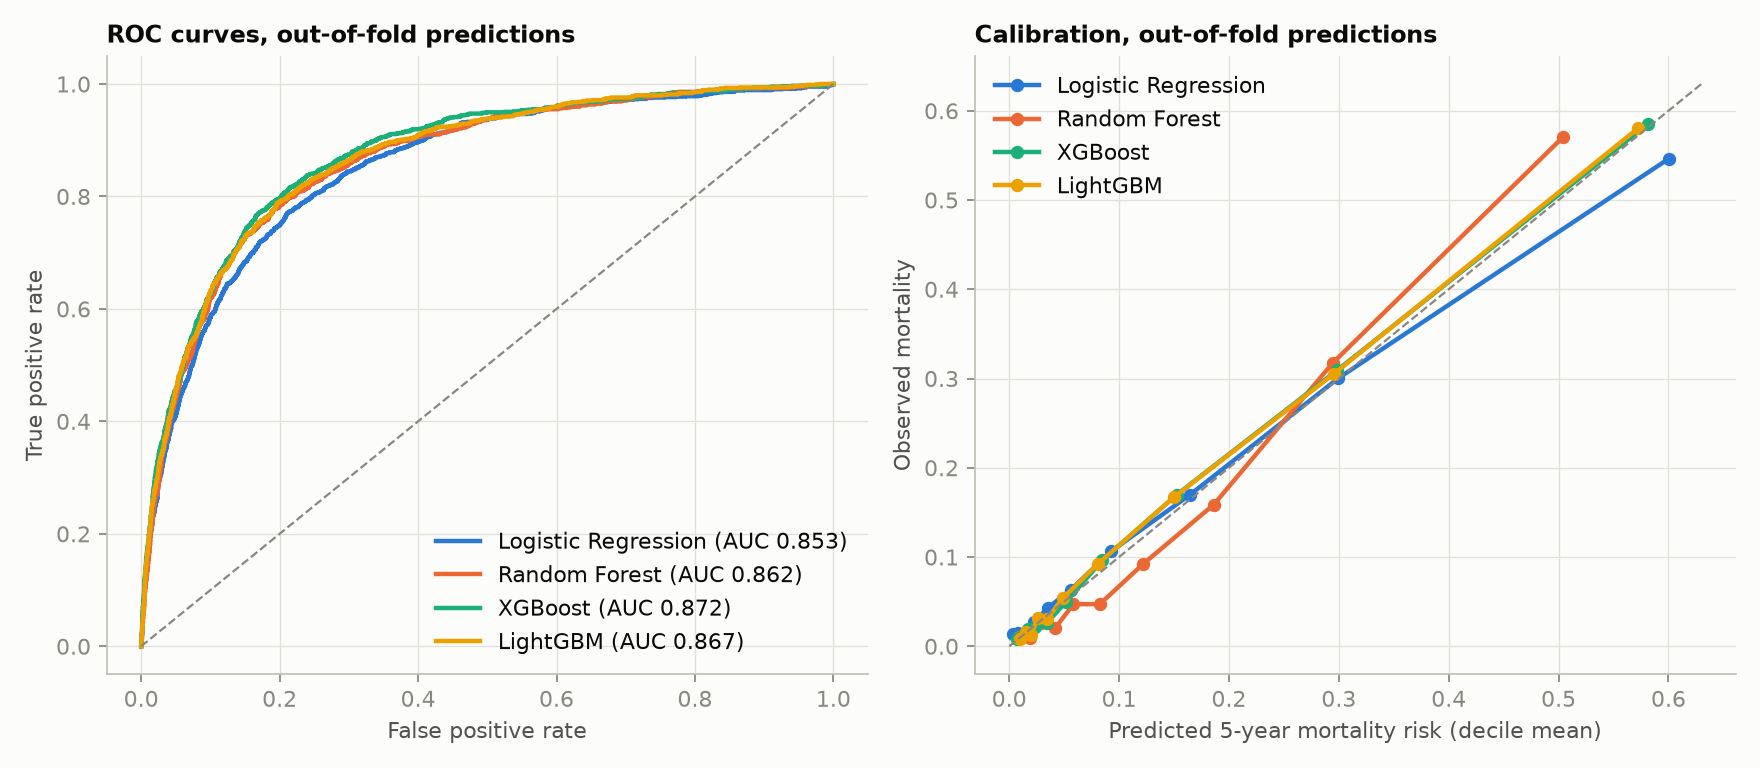

In [8]:
fig("fig_roc_calibration.png", 1000)

## 3. Calibration (paper 2.5) and survival analysis (paper 2.7)

### 3a. Calibration

A calibrated model that says "20% risk" is right about one time in five.

- **Slope** near 1 is ideal; below 1 means predictions are too extreme.
- **CITL** (calibration-in-the-large) near 0 is ideal; negative means risk is over-predicted
  on average.
- The **weighted** columns apply NHANES examination weights, as the paper does for calibration.
  People who were interviewed but not examined have weight 0 and drop out of those columns.

The right-hand panel of the figure above shows the calibration curves.

In [9]:
cv[["Model", "Brier", "CalSlope", "CITL", "Brier (weighted)", "CalSlope (weighted)",
    "CITL (weighted)"]].round(3)

,Model,Brier,CalSlope,CITL,Brier (weighted),CalSlope (weighted),CITL (weighted)
0,Logistic Regression,0.085,0.848,0.002,0.056,0.842,-0.127
1,Random Forest,0.083,1.213,-0.051,0.054,1.321,-0.177
2,XGBoost,0.080,1.004,0.045,0.052,1.012,0.020
3,LightGBM,0.081,1.002,0.057,0.053,1.038,0.009
4,Logistic Regression (unscaled),0.096,0.999,-0.001,0.062,0.954,-0.319
5,XGBoost (paper's five predictors),0.084,1.039,0.003,0.056,1.069,-0.101


### 3b. Kaplan–Meier curves by Troponin-T and NT-proBNP

As in the paper, each biomarker is split into high/low at the cut-off that maximises the Youden
index, chosen in the other four folds and applied to the held-out fold.

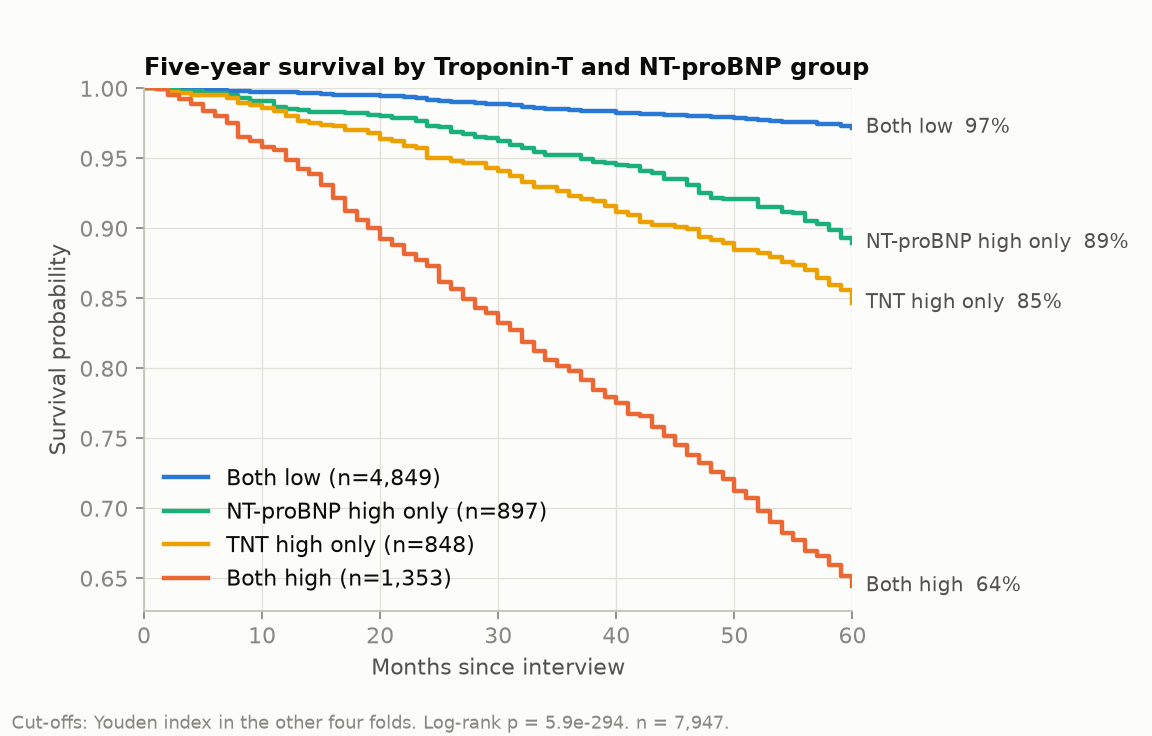

,group,n,deaths,cvd_deaths,other_deaths,mortality %,cvd_mortality %,other_mortality %
0,Both low,4849,136,29,107,2.8,0.6,2.2
1,NT-proBNP high only,897,99,39,60,11.0,4.3,6.7
2,TNT high only,848,130,36,94,15.3,4.2,11.1
3,Both high,1353,481,209,272,35.6,15.4,20.1


In [10]:
fig("fig_km_tnt_ntprobnp.png", 760)
table("km_groups.csv").round(1)

**Five-year cut-offs are higher than the paper's** (Troponin-T about 7.5 ng/L, NT-proBNP about
75–85 pg/mL). The reason is the follow-up window: the paper's Figure 3 follows people for about
250 months, not 60. The diagnostics table shows that cut-offs chosen for death at any time are
much closer to the paper's.

In [11]:
display(table("km_cutoffs.csv").round(2))
table("km_cutoff_diagnostics.csv")

,fold,n_train,n_test,TNT_cutoff,NT-proBNP_cutoff
0,1,6346,1601,12.00,163.6
1,2,6382,1565,10.22,163.3
2,3,6352,1595,11.98,163.3
3,4,6354,1593,10.22,151.3
4,5,6354,1593,12.62,151.3


,Outcome used for Youden index,TNT_cutoff,NT-proBNP_cutoff
0,5-year all-cause death (used here),11.98,151.3
1,5-year cardiovascular death,11.78,160.5
2,Death at any time to 2019,8.17,96.5
3,Median of the biomarker,7.23,74.88
4,"Paper, Table S3 (range over folds)",7.41-7.59,75.31-85.41


**Full follow-up, as in the paper's Figure 3.** Cut-offs by Youden index for death at any time
(to the end of 2019), chosen in the other four folds.

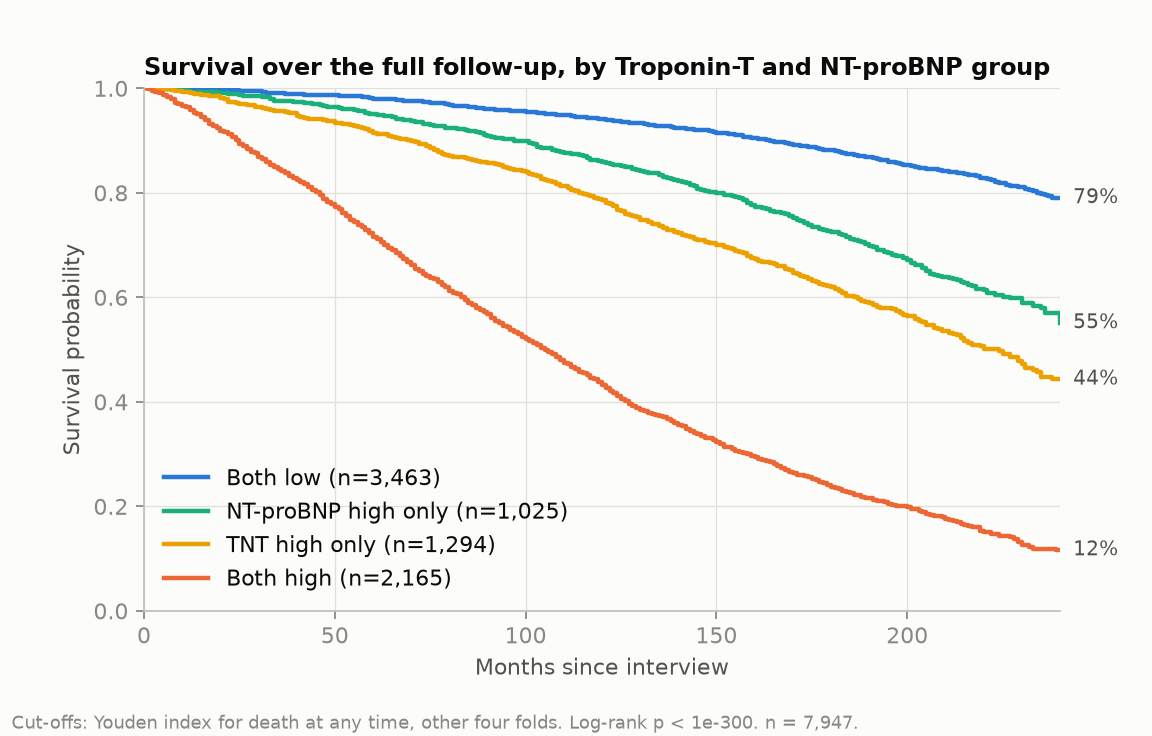

,fold,n_train,n_test,TNT_cutoff,NT-proBNP_cutoff
0,1,6346,1601,8.17,105.2
1,2,6382,1565,7.55,96.5
2,3,6352,1595,8.17,111.1
3,4,6354,1593,8.31,96.5
4,5,6354,1593,8.31,110.9


,group_full,n,deaths,survival at 240 months %
0,Both low,3463,589.0,79.0
1,NT-proBNP high only,1025,386.0,55.1
2,TNT high only,1294,620.0,44.3
3,Both high,2165,1796.0,11.6


In [12]:
fig("fig_km_full_followup.png", 760)
display(table("km_cutoffs_full_followup.csv").round(2))
table("km_groups_full_followup.csv").round(1)

### 3c. Cardiovascular and non-cardiovascular death (competing risks)

Cardiovascular death = underlying cause "diseases of heart" or "cerebrovascular diseases"
(`UCOD_LEADING` 001 or 005 in the public linked mortality file). Curves are Aalen–Johansen
cumulative incidence, where death from the other cause is a competing event. Group differences
are tested with Gray's test. Nobody in this cohort is lost to follow-up before five years, and
in that situation Gray's test is exactly a log-rank test in which people who die of the
competing cause stay at risk.

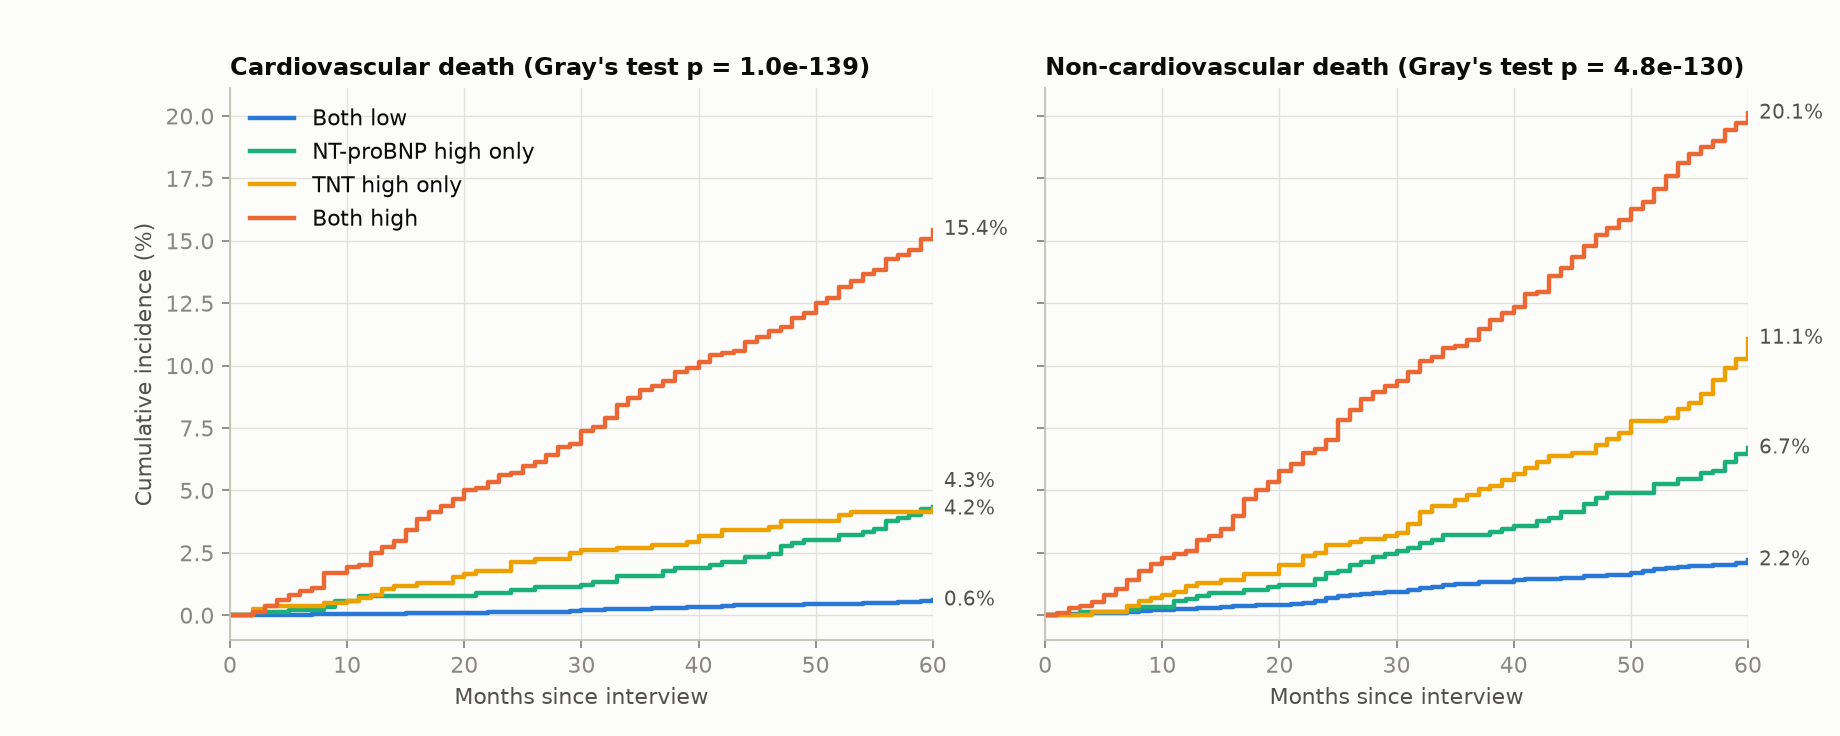

,Outcome,Test,p
0,All-cause death,Log-rank,5.9e-294
1,Cardiovascular death,Gray (competing risk),1.0e-139
2,Non-cardiovascular death,Gray (competing risk),4.8e-130
3,"All-cause death, full follow-up",Log-rank,< 1e-300


In [13]:
fig("fig_cumulative_incidence.png", 1000)
t = table("survival_tests.csv")
t["p"] = t["p"].map(lambda v: f"{v:.1e}" if v > 0 else "< 1e-300")
t

## 4. A simpler model from feature importance (paper 2.8)

The paper keeps five predictors: age, Troponin-T, NT-proBNP, physical activity and gender. It
chose them from SHAP importance on training data, stability across subgroups, availability and
parsimony.

**Our own ranking.** Data are split 70/30. A 134-predictor XGBoost model is fitted on the
training part only, and predictors are ranked by mean |SHAP| overall and inside each subgroup.

In [14]:
rank = table("simple_model_feature_ranking.csv", index_col=0)
print("Top five by our SHAP ranking:", ", ".join(rank["Paper variable"].head(5)))
print("Paper's five:                 Age, Troponin-T, NT-proBNP, Physical activity, Gender")
print("Same five predictors:", "yes" if info["our_top_five_equals_papers_five"] else "no")
rank.head(12).round(3)

Top five by our SHAP ranking: Age, Troponin-T, Physical activity, NT-proBNP, Gender
Paper's five:                 Age, Troponin-T, NT-proBNP, Physical activity, Gender
Same five predictors: yes


,Paper variable,Mean |SHAP|,All,Men,Women,Age under 65,Age 65+,Prior CVD,No prior CVD,Worst subgroup rank,In paper's five
RIDAGEYR,Age,0.641,1,1,1,1,2,2,1,2,True
SSTNT,Troponin-T,0.550,2,2,2,2,1,1,2,2,True
PAQ180,Physical activity,0.310,3,3,3,3,3,3,3,3,True
SSBNP,NT-proBNP,0.259,4,4,5,4,4,4,4,5,True
RIAGENDR,Gender,0.207,5,5,4,5,5,5,5,5,True
BMXWAIST,Waist circumference,0.179,6,9,6,6,6,7,6,9,False
BMXCALF,Calf circumference,0.164,7,6,8,9,7,6,7,9,False
LBXRDW,Red cell distribution width,0.153,8,8,7,7,11,15,9,15,False
MET_MIN_30D_CAND,MET score,0.153,9,7,9,8,10,16,8,16,False
RIDRETH1,Race,0.139,10,13,10,11,9,9,10,13,False


**Final model, set up as in the paper:** XGBoost, 70/30 split, 15% of the training part held out
for early stopping and for isotonic recalibration, class imbalance handled with
`scale_pos_weight`. Evaluated once on the 30% test set. When our top five are the same set as the
paper's five, there is only one simple model and it is shown once.

"Raw" rows show why recalibration is needed: class weighting makes the model over-predict risk
(strongly negative CITL), and isotonic regression brings the average back.

Paper's reported test results for its five-predictor model: ROC-AUC 0.841, PR-AUC 0.510;
weighted Brier 0.097 before and 0.055 after isotonic recalibration; slope 0.898 → 0.479;
CITL −1.807 → −0.725.

In [15]:
table("final_model_test_metrics.csv").round(3)

,Model,Predictions,Test n,ROC-AUC,PR-AUC,Brier,Brier (weighted),Slope,CITL,Slope (weighted),CITL (weighted)
0,Paper's five predictors (also our top five),Raw,2988,0.828,0.496,0.141,0.096,0.707,-1.691,0.670,-1.714
1,Paper's five predictors (also our top five),Isotonic,2988,0.822,0.475,0.086,0.057,0.594,0.051,0.489,-0.057
2,All 134 predictors,Raw,2988,0.855,0.522,0.099,0.061,0.602,-0.833,0.631,-0.580
3,All 134 predictors,Isotonic,2988,0.852,0.498,0.084,0.054,0.567,0.107,0.539,0.151


Operating point with PPV fixed at 40%. Paper (test, weighted, isotonic): threshold 0.44,
sensitivity 0.316, specificity 0.976, NPV 0.947, 4.6% of people flagged.

In [16]:
table("final_model_operating_points.csv").round(3)

,Model,Setting,Threshold,Sensitivity,Specificity,PPV,NPV,Predicted positive rate
0,Paper's five predictors (also our top five),"Test, weighted, isotonic",0.250,0.417,0.959,0.453,0.953,0.069
1,Paper's five predictors (also our top five),"Test, unweighted, isotonic",0.250,0.559,0.915,0.494,0.933,0.147
2,All 134 predictors,"Test, weighted, isotonic",0.194,0.536,0.938,0.413,0.961,0.097
3,All 134 predictors,"Test, unweighted, isotonic",0.108,0.716,0.843,0.405,0.952,0.230


Cross-validated comparison of the simple models with the full model (same folds as section 2):

In [17]:
cv[cv["Model"].str.startswith("XGBoost")][["Model", "Predictors", "ROC-AUC", "PR-AUC", "Brier",
                                          "Sens@PPV40", "Spec@Sens85"]].round(3)

,Model,Predictors,ROC-AUC,PR-AUC,Brier,Sens@PPV40,Spec@Sens85
2,XGBoost,134,0.872,0.546,0.080,0.773,0.738
5,XGBoost (paper's five predictors),5,0.854,0.499,0.084,0.690,0.714


## 5. Research question: do models with similar accuracy agree on what matters for each person?

For 300 held-out people in each of the five folds (1,500 in total) every model's prediction is
explained with SHAP, at the level of the 134 original predictors (one-hot columns are summed back).

- **Top-1 feature agreement**: share of people for whom two models name the same most important predictor.
- **Top-5 overlap**: average share of the five most important predictors that two models have in common.
- **Correlated groups**: the same top-1 comparison after merging predictors that correlate at
  |Spearman| ≥ 0.7, so that two near-copies of one measurement count as the same answer.

Three reference comparisons show how much disagreement is noise or preprocessing:

- **Same model, new random seed**: the ceiling. Two fits of one algorithm on the same data.
- **Same model, imputed vs raw inputs**: XGBoost given the imputed table that GLM, Random
  Forest and LightGBM use, against XGBoost given the missing values as they are.
- **Different models, same imputed inputs**: XGBoost and Random Forest when both receive the
  identical imputed table.

Merging correlated predictors usually raises agreement, but it can lower it: when a model spreads
importance thinly over a large family of near-copies (the 30 DNA-methylation variables after
imputation), the family's summed importance can overtake that person's single top predictor.

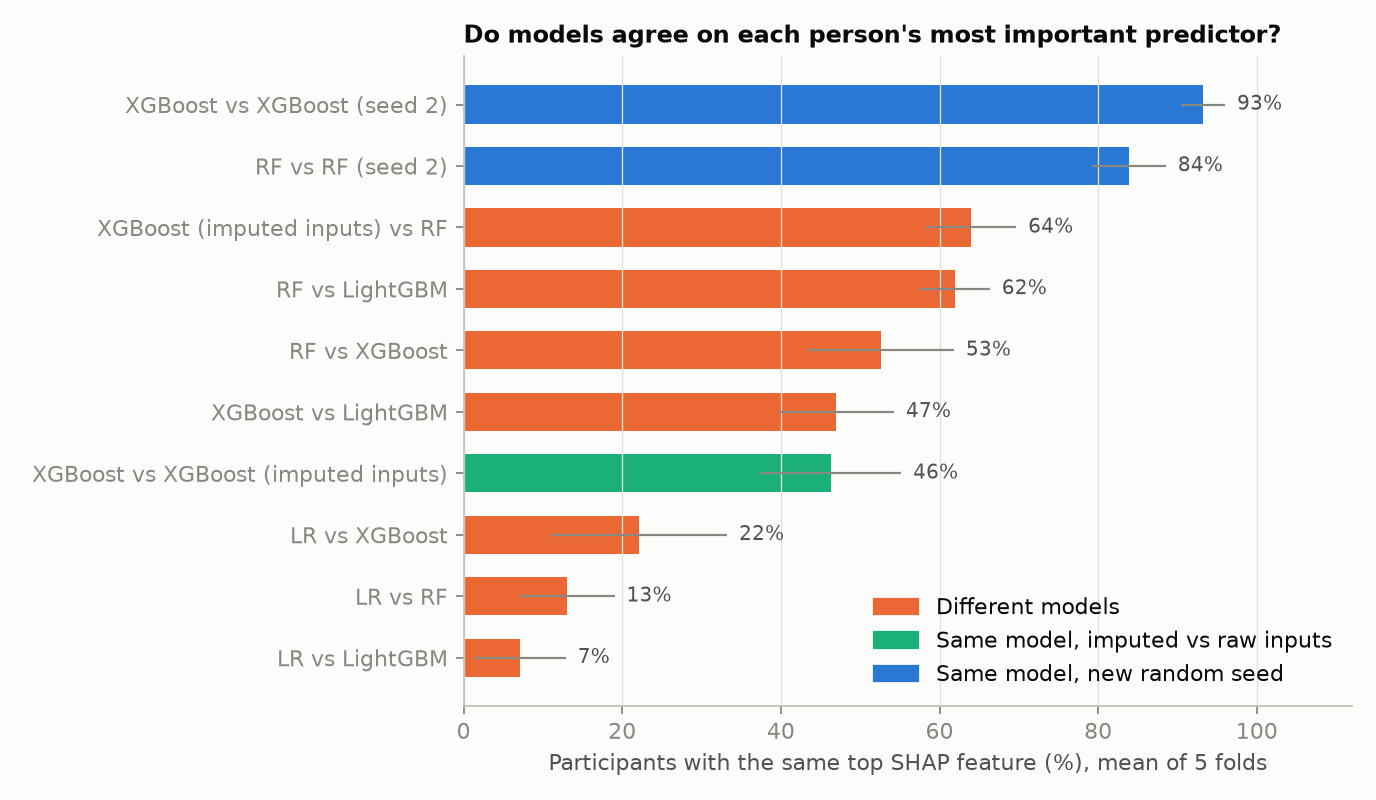

,Model A,Model B,Type,Top-1 feature agreement,Top-5 overlap,Mean Spearman |SHAP|,Top-1 agreement (correlated groups),Top-1 SD across folds
0,Logistic Regression,Random Forest,Different models,0.130,0.193,0.160,0.610,0.060
1,Logistic Regression,XGBoost,Different models,0.221,0.208,0.021,0.530,0.111
2,Logistic Regression,LightGBM,Different models,0.071,0.204,0.109,0.282,0.058
3,Random Forest,XGBoost,Different models,0.526,0.537,0.308,0.656,0.092
4,Random Forest,LightGBM,Different models,0.619,0.586,0.483,0.409,0.044
5,XGBoost,LightGBM,Different models,0.470,0.624,0.509,0.573,0.073
6,XGBoost,XGBoost (seed 2),"Same model, new random seed",0.932,0.840,0.820,0.911,0.028
7,Random Forest,Random Forest (seed 2),"Same model, new random seed",0.839,0.845,0.788,0.937,0.047
8,XGBoost,XGBoost (imputed inputs),"Same model, imputed vs raw inputs",0.463,0.685,0.547,0.545,0.089
9,XGBoost (imputed inputs),Random Forest,"Different models, same imputed inputs",0.640,0.586,0.483,0.331,0.057


In [18]:
fig("fig_shap_agreement.png", 860)
ag = table("shap_agreement.csv")
ag.round(3)

Which predictor does each model put first, and for what share of people?

In [19]:
table("shap_top1_feature_share.csv", index_col=0).head(10).round(3)

,Logistic Regression,Random Forest,XGBoost,LightGBM
Age,0.251,0.254,0.627,0.173
Troponin-T,0.002,0.533,0.319,0.765
NT-proBNP,0.003,0.034,0.017,0.007
Physical activity,0.028,0.059,0.017,0.025
Platelet count,0.000,0.000,0.005,0.003
Red cell distribution width,0.000,0.009,0.003,0.003
Serum glucose,0.064,0.001,0.002,0.000
Testosterone,0.001,0.000,0.002,0.000
Resting heart rate,0.000,0.000,0.001,0.000
Arm circumference,0.008,0.000,0.001,0.000


Local explanations: the three most important predictors for individual participants, by model.

In [20]:
table("shap_local_top3.csv").head(8)

,SEQN,Logistic Regression #1,Logistic Regression #2,Logistic Regression #3,Random Forest #1,Random Forest #2,Random Forest #3,XGBoost #1,XGBoost #2,XGBoost #3,LightGBM #1,LightGBM #2,LightGBM #3
0,13258.0,Waist circumference,Age,DNA methylation: CD8TPP,Troponin-T,Age,DNA methylation: ZhangAge,Age,Troponin-T,Lead,Troponin-T,Age,Arm circumference
1,25630.0,Age,DNA methylation: CystatinCMort,DNA methylation: GrimAge2Mort,Physical activity,DNA methylation: ZhangAge,DNA methylation: logA1CMort,Age,Physical activity,Troponin-T,Troponin-T,Age,Physical activity
2,5889.0,Serum glucose,Plasma glucose,Heart rate recovery 3min,NT-proBNP,Troponin-T,DNA methylation: ZhangAge,Platelet count,Age,Troponin-T,Troponin-T,Platelet count,NT-proBNP
3,16731.0,LDH,Age,Waist circumference,Troponin-T,Thigh circumference,DNA methylation: ZhangAge,Age,Physical activity,Troponin-T,Troponin-T,Age,Physical activity
4,17214.0,Age,Thigh circumference,Hemoglobin,Troponin-T,Cystatin,DNA methylation: LeptinMort,Troponin-T,Age,Physical activity,Troponin-T,Age,Red cell distribution width
5,15116.0,Waist circumference,DNA methylation: CystatinCMort,DNA methylation: GrimAge2Mort,Troponin-T,Physical activity,DNA methylation: ZhangAge,Age,Physical activity,Resting heart rate,Troponin-T,Resting heart rate,Physical activity
6,29999.0,Hypertension history,Age,DNA methylation: NeuPP,NT-proBNP,Troponin-T,Age,Age,NT-proBNP,Troponin-T,Troponin-T,Age,NT-proBNP
7,30625.0,Serum glucose,Hemoglobin,Heart failure history,Heart failure history,Troponin-T,Physical activity,Troponin-T,Age,NT-proBNP,Troponin-T,Heart failure history,DNA methylation: ZhangAge


In [21]:
def row(a, b):
    r = ag[(ag["Model A"] == a) & (ag["Model B"] == b)].iloc[0]
    return 100 * r["Top-1 feature agreement"], 100 * r["Top-1 agreement (correlated groups)"]

print("Share of people with the same top predictor (raw / after merging correlated predictors)")
for a, b, label in [("XGBoost", "XGBoost (seed 2)", "XGBoost refit with a new seed"),
                    ("Random Forest", "Random Forest (seed 2)", "Random Forest refit with a new seed"),
                    ("XGBoost", "LightGBM", "XGBoost (raw inputs) vs LightGBM (imputed)"),
                    ("Random Forest", "LightGBM", "Random Forest vs LightGBM, same imputed inputs"),
                    ("XGBoost", "XGBoost (imputed inputs)", "XGBoost: raw vs imputed inputs"),
                    ("XGBoost (imputed inputs)", "Random Forest", "XGBoost vs RF, same imputed inputs"),
                    ("Random Forest", "XGBoost", "XGBoost vs Random Forest"),
                    ("Logistic Regression", "XGBoost", "XGBoost vs GLM"),
                    ("Logistic Regression", "Random Forest", "Random Forest vs GLM")]:
    t1, g = row(a, b)
    print(f"  {label:48s} {t1:5.1f}%  / {g:5.1f}%")

Share of people with the same top predictor (raw / after merging correlated predictors)
  XGBoost refit with a new seed                     93.2%  /  91.1%
  Random Forest refit with a new seed               83.9%  /  93.7%
  XGBoost (raw inputs) vs LightGBM (imputed)        47.0%  /  57.3%
  Random Forest vs LightGBM, same imputed inputs    61.9%  /  40.9%
  XGBoost: raw vs imputed inputs                    46.3%  /  54.5%
  XGBoost vs RF, same imputed inputs                64.0%  /  33.1%
  XGBoost vs Random Forest                          52.6%  /  65.6%
  XGBoost vs GLM                                    22.1%  /  53.0%
  Random Forest vs GLM                              13.0%  /  61.0%


## 6. Feature importance beyond SHAP

Three measures, each computed for all four models:

| Measure | What it asks | Computed on |
|---|---|---|
| **SHAP** | How much does this predictor move each person's prediction? | 1,500 held-out people |
| **Permutation importance** | How much does held-out ROC-AUC fall when this predictor is shuffled? | every held-out fold, 3 shuffles |
| **Built-in importance** | The model's own bookkeeping: total gain (XGBoost, LightGBM), impurity decrease (Random Forest), size of standardized coefficient (GLM) | training folds |

Permutation importance measures what the model *needs*; SHAP and built-in importance measure what
the model *uses*. When several predictors carry the same information, a model can use one heavily
without needing it.

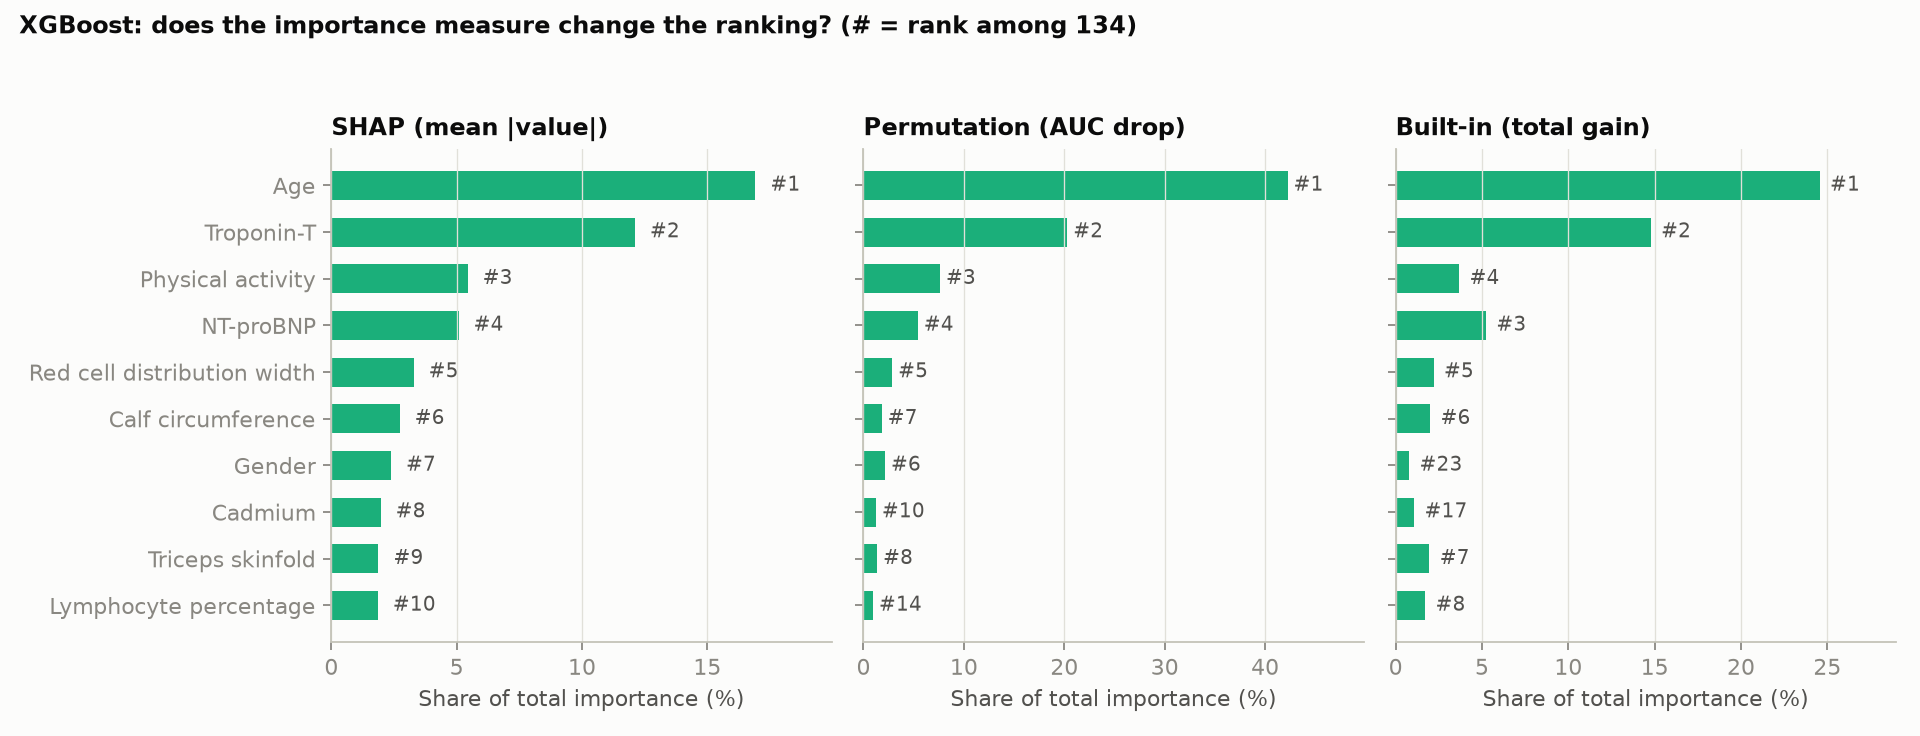

,#1,#2,#3,#4,#5
LR | SHAP,Age,Serum glucose,Gender,Physical activity,Albumin
LR | Permutation,Age,Serum glucose,Heart rate recovery 1min,Albumin,Physical activity
LR | Built-in,Income,Age,Serum glucose,Physical activity,Plasma glucose
RF | SHAP,Troponin-T,Age,Physical activity,Beta 2 Microglobulin,DNA methylation: ZhangAge
RF | Permutation,Age,Troponin-T,Physical activity,NT-proBNP,Cerebrovascular event history
RF | Built-in,Troponin-T,Age,NT-proBNP,Beta 2 Microglobulin,Physical activity
XGBoost | SHAP,Age,Troponin-T,Physical activity,NT-proBNP,Red cell distribution width
XGBoost | Permutation,Age,Troponin-T,Physical activity,NT-proBNP,Red cell distribution width
XGBoost | Built-in,Age,Troponin-T,NT-proBNP,Physical activity,Red cell distribution width
LightGBM | SHAP,Troponin-T,Age,Physical activity,Red cell distribution width,Cotinine


In [22]:
fig("fig_importance_measures_xgboost.png", 1100)
table("importance_top5_by_measure.csv").T.rename(columns=lambda i: f"#{i + 1}")

Do the three measures agree **within** one model? (Spearman correlation of the 134 rankings;
share of the top ten in common.)

In [23]:
table("importance_agreement_between_measures.csv").round(3)

,Model,Measure A,Measure B,Spearman of rankings,Top-10 overlap
0,Logistic Regression,SHAP,Permutation,0.912,0.9
1,Logistic Regression,SHAP,Built-in,0.914,0.7
2,Logistic Regression,Permutation,Built-in,0.911,0.8
3,Random Forest,SHAP,Permutation,0.358,0.7
4,Random Forest,SHAP,Built-in,0.856,1.0
5,Random Forest,Permutation,Built-in,0.240,0.7
6,XGBoost,SHAP,Permutation,0.577,0.9
7,XGBoost,SHAP,Built-in,0.978,0.8
8,XGBoost,Permutation,Built-in,0.542,0.8
9,LightGBM,SHAP,Permutation,0.502,0.8


Do the four models agree with each other **under each measure**? This is the global version of
the research question in section 5.

In [24]:
b = table("importance_agreement_between_models.csv")
display(b.pivot_table(index=["Model A", "Model B"], columns="Measure",
                      values="Spearman of rankings", sort=False).round(3))
b.pivot_table(index=["Model A", "Model B"], columns="Measure", values="Top-10 overlap",
              sort=False).round(2)

Measure                             SHAP  Permutation  Built-in
Model A             Model B                                    
Logistic Regression Random Forest  0.151       -0.056     0.118
                    XGBoost       -0.124        0.070    -0.091
                    LightGBM       0.001        0.053    -0.028
Random Forest       XGBoost        0.350        0.348     0.530
                    LightGBM       0.610        0.460     0.745
XGBoost             LightGBM       0.752        0.451     0.782

Measure                            SHAP  Permutation  Built-in
Model A             Model B                                   
Logistic Regression Random Forest   0.2          0.2       0.2
                    XGBoost         0.3          0.3       0.2
                    LightGBM        0.2          0.2       0.2
Random Forest       XGBoost         0.5          0.5       0.5
                    LightGBM        0.6          0.7       0.6
XGBoost             LightGBM        0.7          0.7       0.7

**Partial dependence** shows the shape of an effect: the average predicted risk if everyone had
a given value of one predictor, with everything else unchanged.

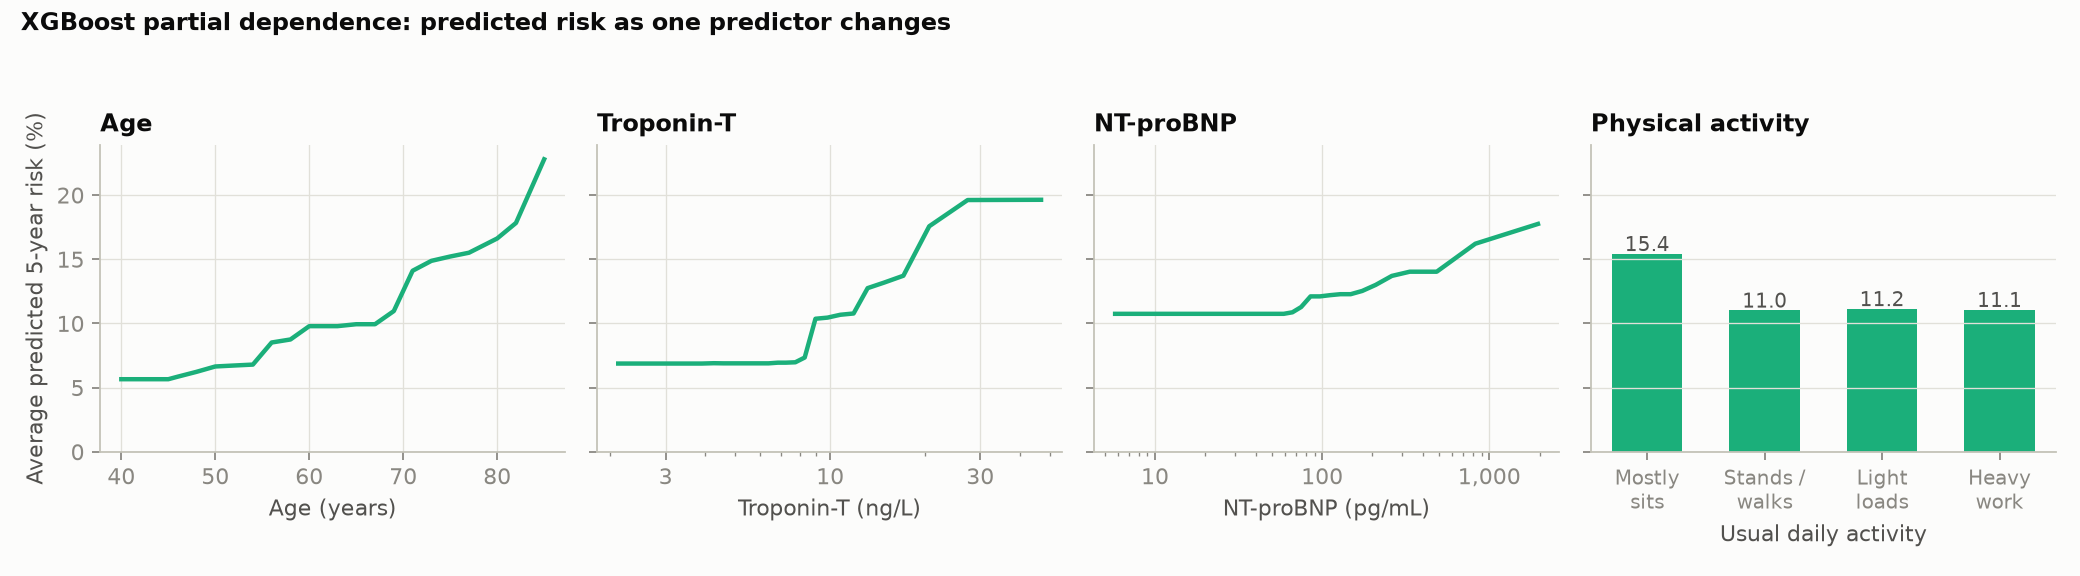

In [25]:
fig("fig_partial_dependence_xgboost.png", 1100)

## 7. SHAP replication (paper 2.6)

As in the paper, SHAP values come from the XGBoost model and are computed **inside the training
folds only** (2,000 people per fold), then averaged over the five folds. The paper reports age
and Troponin-T as first and second in every subgroup, with NT-proBNP also leading.

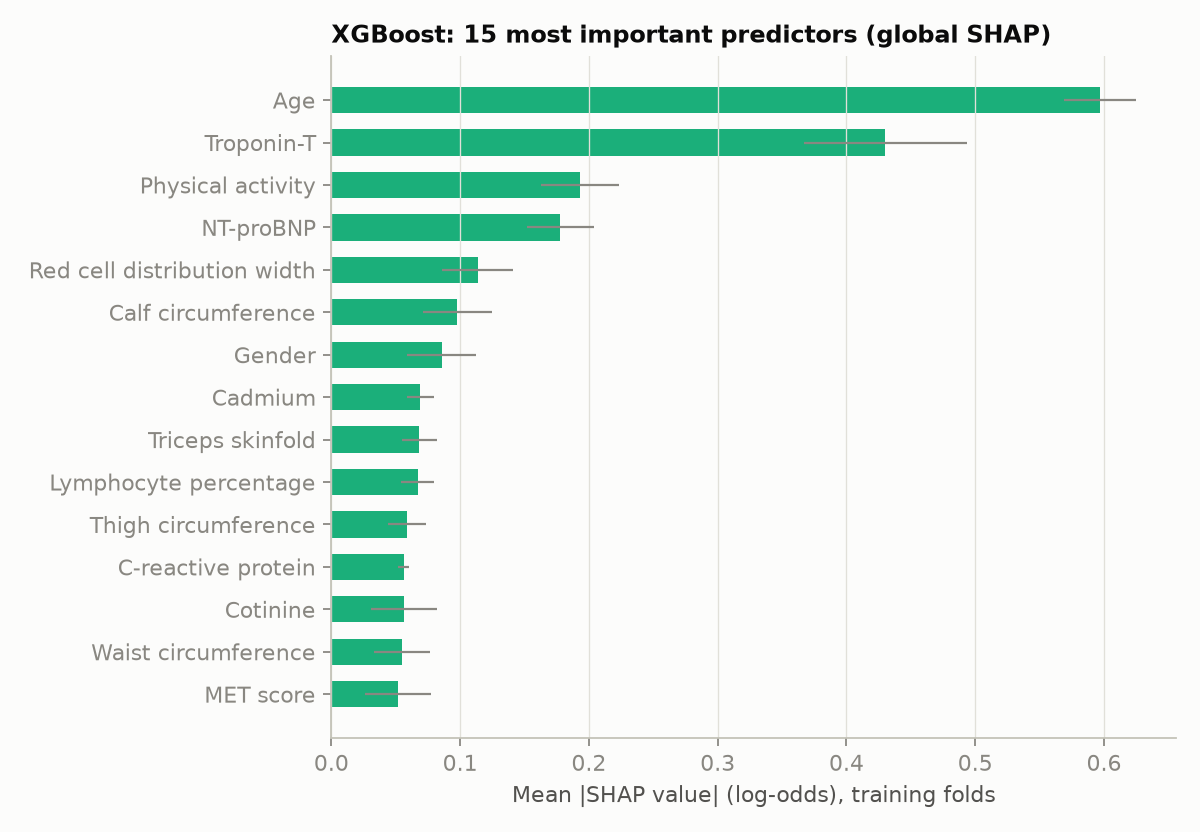

,Paper variable,Mean |SHAP|,SD across folds,Rank,Rank: Men,Rank: Women,Rank: Age under 65,Rank: Age 65+,Rank: Prior CVD,Rank: No prior CVD
RIDAGEYR,Age,0.597,0.028,1,1,1,1,1,1,1
SSTNT,Troponin-T,0.430,0.063,2,2,2,2,2,2,2
PAQ180,Physical activity,0.193,0.030,3,4,3,4,3,3,3
SSBNP,NT-proBNP,0.178,0.026,4,3,4,3,4,4,4
LBXRDW,Red cell distribution width,0.113,0.028,5,5,5,5,6,5,5
BMXCALF,Calf circumference,0.098,0.027,6,6,6,6,7,6,6
RIAGENDR,Gender,0.086,0.027,7,7,7,8,5,9,7
LBXBCD,Cadmium,0.069,0.010,8,8,10,7,13,13,8
BMXTRI,Triceps skinfold,0.068,0.014,9,10,8,9,9,10,9
LBXLYPCT,Lymphocyte percentage,0.067,0.013,10,9,9,11,8,11,10


In [26]:
tr = table("shap_training_folds_ranking.csv", index_col=0)
fig("fig_shap_global_xgboost.png", 760)
tr.head(12).round(3)

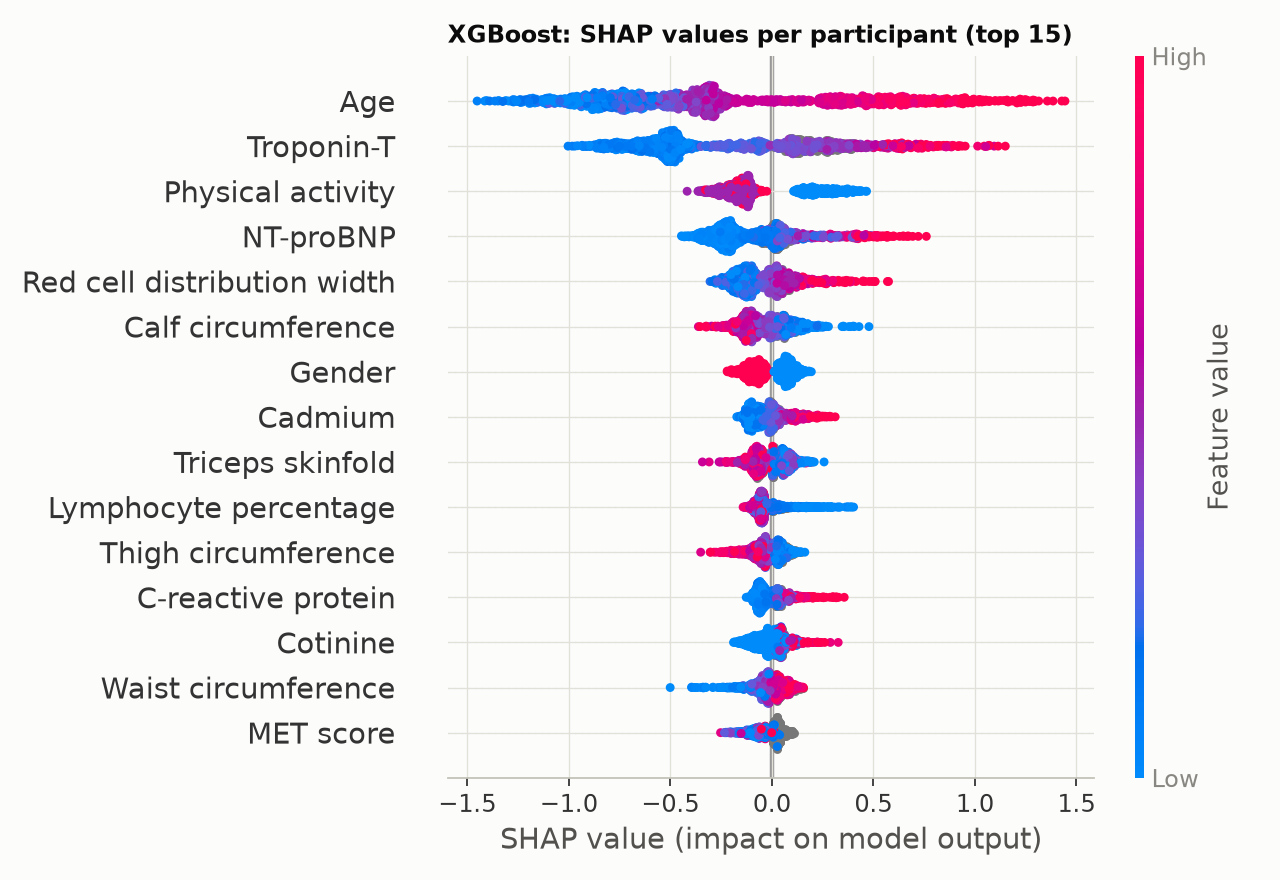

In [27]:
fig("fig_shap_beeswarm_xgboost.png", 800)

**Top ten predictors: correlation and clustering** (paper Figure S2). Spearman correlations,
ordered by average-linkage hierarchical clustering. The paper describes three groups: a cardiac
injury and stress group (Troponin-T, NT-proBNP, age, RDW), a body-composition group, and a
demographic / immune / activity group.

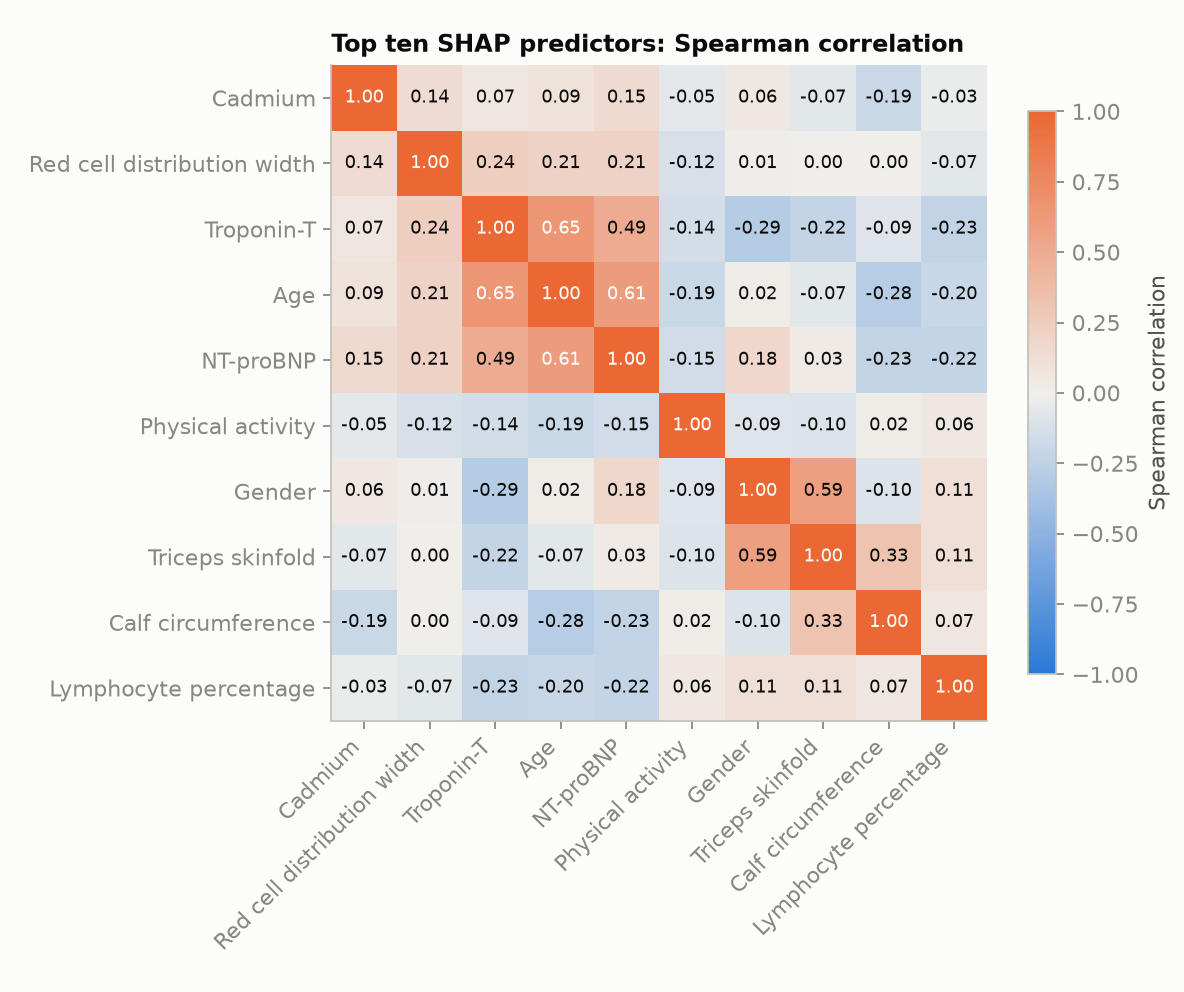

In [28]:
fig("fig_top10_correlation.png", 760)

**Troponin-T × NT-proBNP interaction** (paper Table S2 and Figure S3). SHAP interaction values
measure how much the two biomarkers change each other's effect. The paper reports values that
round to zero and concludes the effects add up without amplifying each other. The last column
gives the size of Troponin-T's own effect for scale.

,fold,mean(|interaction|),mean(interaction),median(interaction),95% quantile(|interaction|),mean(|TNT main effect|)
0,1,0.0350,-0.0095,0.0037,0.0828,0.5888
1,2,0.0242,-0.0109,-0.0066,0.0628,0.6397
2,3,0.0409,-0.0262,-0.0120,0.1178,0.4848
3,4,0.0471,-0.0308,-0.0109,0.1344,0.4756
4,5,0.0271,-0.0095,0.0032,0.0742,0.5015


Interaction is 6.5% of the size of Troponin-T's own effect, on average.


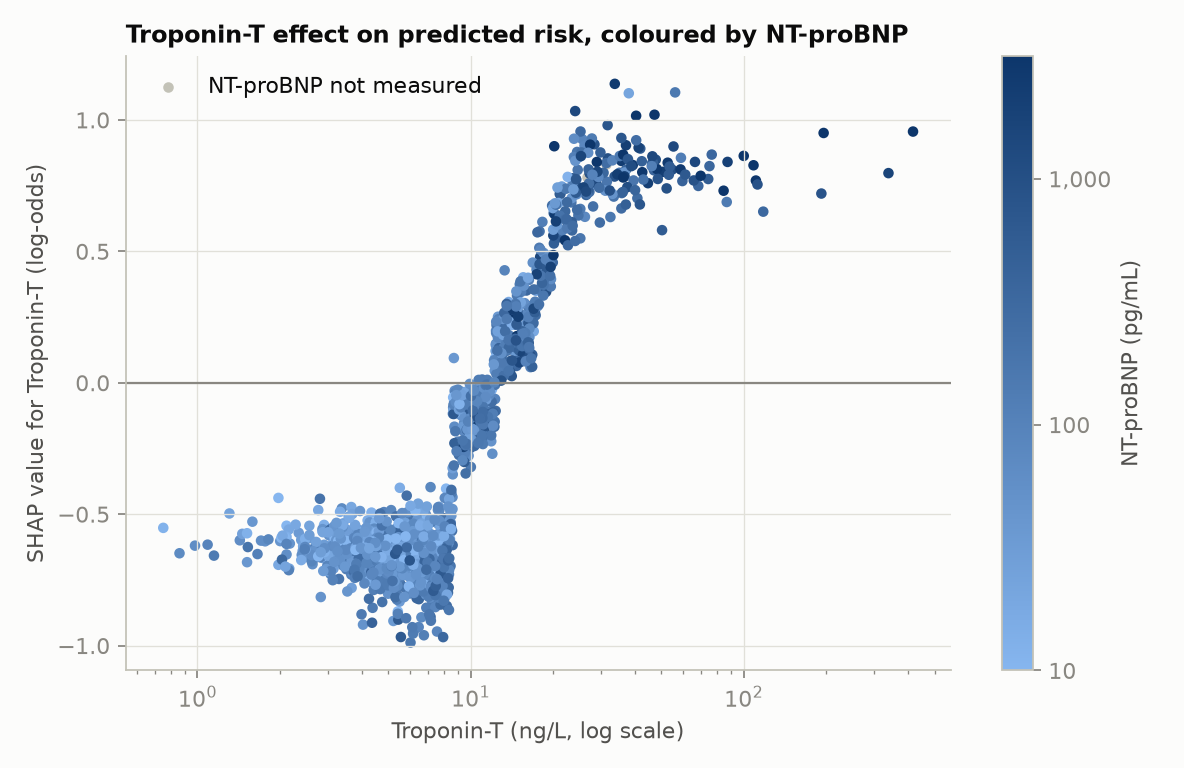

In [29]:
inter = table("shap_interaction_tnt_ntprobnp.csv")
display(inter.round(4))
print(f"Interaction is {100 * inter['mean(|interaction|)'].mean() / inter['mean(|TNT main effect|)'].mean():.1f}% "
      "of the size of Troponin-T's own effect, on average.")
fig("fig_shap_dependence_tnt.png", 760)

## 8. Validation across survey cycles (paper 2.9)

Train on NHANES 1999–2002, test on 2003–2004. The main model is the five-predictor XGBoost;
Models A–C are the paper's logistic-regression benchmarks.

Paper: main model AUC 0.853 (slope 0.96, CITL −1.74, Brier 0.149); Model A 0.802; Model B 0.812;
Model C 0.817. NRI of the main model over A / B / C: 0.095 / 0.069 / 0.062; IDI: 0.236 / 0.224 / 0.205.

NRI and IDI here are the continuous (category-free) versions, as in the paper. The values still
differ greatly. The paper's main model was class-weighted (hence its CITL of −1.74), which changes
IDI in particular, but we cannot reproduce its numbers.

In [30]:
table("temporal_validation.csv").round(3)

,Model,Train n,Test n,AUC,CITL,Slope,Brier,NRI (main vs this),IDI (main vs this)
0,"Main model: XGBoost, five predictors",6665,3292,0.855,0.104,1.011,0.088,NaN,NaN
1,"XGBoost, 134 predictors",6665,3292,0.874,0.282,1.055,0.085,NaN,NaN
2,Model A: age,6665,3292,0.801,0.063,1.021,0.100,0.521,0.099
3,Model B: age + gender,6665,3292,0.811,0.062,1.042,0.098,0.496,0.087
4,Model C: age + physical activity,6665,3292,0.817,0.082,0.973,0.097,0.370,0.069


## 9. What is still open

**Needs the authors (cannot be settled from the paper, its supplement or CDC documentation):**

- **MET score** and **heart-rate increment**: formulas are not given. Results use
  MET-minutes over 30 days and peak minus resting heart rate.
- **Heart-rate recovery**, **eGFR equation**, **medication flags**: current definitions kept; the
  paper's are unknown.
- **Heart attack**: the text says myocardial infarction / heart attack, the supplement's table says
  "coronary artery disease history", and neither NHANES item alone reproduces Table 1.
- **Thyroid hormones**: the Methods list TSH and thyroxine among the 134 variables, but the
  supplement's table of 134 does not contain them. They are left out here.
- **Glycated albumin**: the paper's figures label it "GA(%)"; the supplement's counts match the
  g/dL variable, which is used here.
- **Laboratory counts**: for cadmium, lead, folate, B12, cotinine, mercury and the fasting labs
  the paper reports far fewer measured people than the public files contain.
- **Size of the paper's SHAP model**: its Figures 1 and 2 show 14 named features plus "Sum of 36
  other features", i.e. 50 input columns, fewer than a 134-variable model would have.
- **Hyperparameters and random seeds** are not reported, so exact numbers cannot match.

Section 1 shows that none of the definition choices we could test moves XGBoost's ROC-AUC by more
than about 0.001.

**Known departures from the paper:**

- Imputed values are bounded to the observed range (section 1).
- Models in sections 2, 5, 6 and 7 are not class-weighted (the paper's Table 2 results are
  consistent with that); the final model in section 4 is class-weighted, as in the paper.
- Survey weights are the standard six-year examination weights. The paper's weighted population
  totals do not match these, so its weighting scheme is unknown.
- NRI and IDI: ours differ greatly from the paper's although both are described as continuous.

**Not done yet:** separate models and SHAP rankings for cardiovascular and non-cardiovascular
death (the paper's Figure 1 B and C).

**Evidence for every variable:** `results/paper134_evidence_report_v0.1.xlsx`.